# Load data and plot a graph

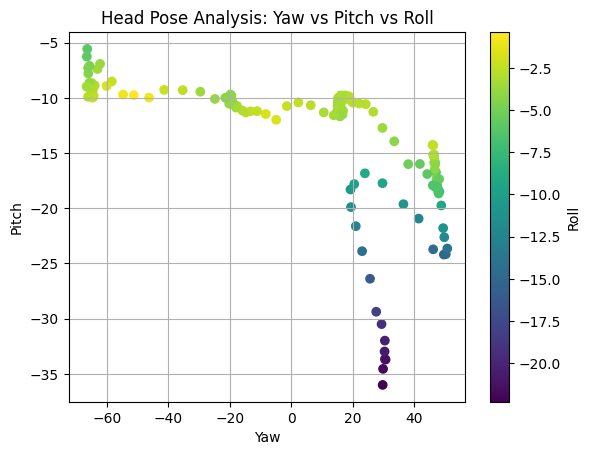

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

angle_df = pd.read_csv("./head_pose_data_01.csv")
angle_df

# Plot yaw and pitch points as clusters with roll as color
plt.scatter(angle_df['yaw'], angle_df['pitch'], c=angle_df['roll'], cmap='viridis')
plt.xlabel('Yaw')
plt.ylabel('Pitch')
plt.title('Head Pose Analysis: Yaw vs Pitch vs Roll')
plt.colorbar(label='Roll')
plt.grid(True)
plt.show()

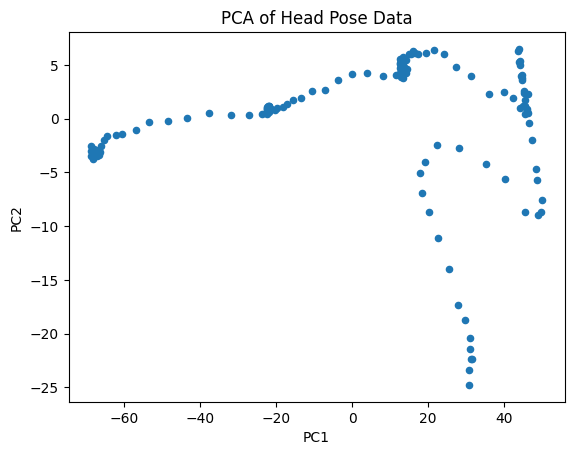

In [3]:
# Perform PCA on yaw, pitch and roll data to find 2 main components
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
principal_components = pca.fit_transform(angle_df[['yaw', 'pitch', 'roll']].dropna())
pc_df = pd.DataFrame(data=principal_components, columns=['PC1', 'PC2'])
pc_df.plot.scatter(x='PC1', y='PC2', title='PCA of Head Pose Data')
plt.show()

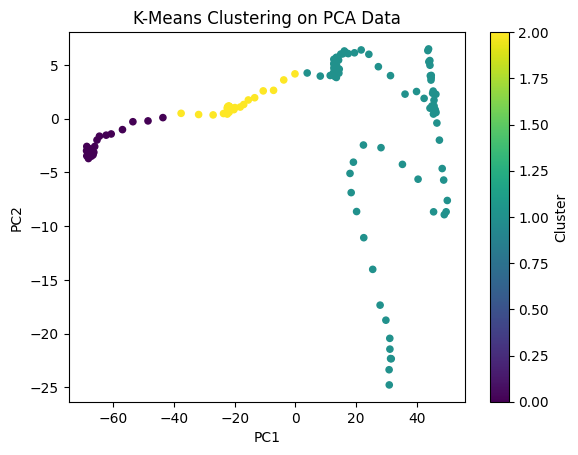

In [4]:
# Perform k-means clustering with k=3 on PCA data
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3)
kmeans.fit(pc_df)
pc_df['Cluster'] = kmeans.labels_
pc_df.plot.scatter(x='PC1', y='PC2', c='Cluster', colormap='viridis', title='K-Means Clustering on PCA Data')
plt.show()

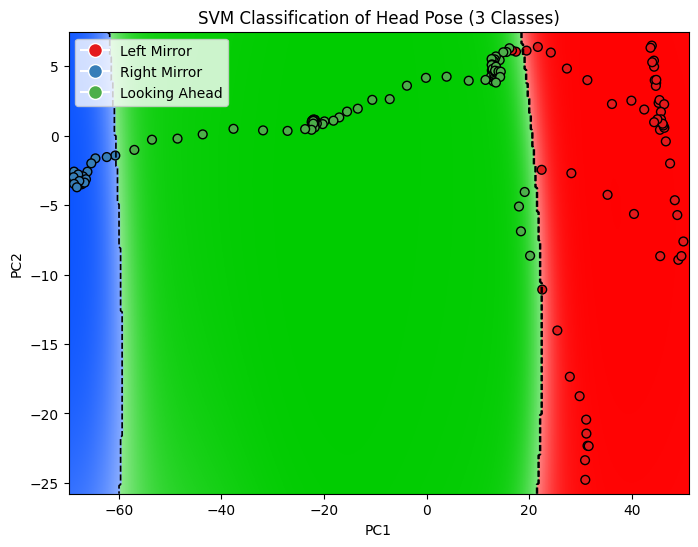

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os
base_dir = 'data/directions_cut'
sub_dirs = ['left_mirror', 'right_mirror', 'looking_ahead']
file_dict = {}
for sub_dir in sub_dirs:
    dir_path = os.path.join(base_dir, sub_dir)
    file_dict[sub_dir] = os.listdir(dir_path)

# Extract just the frame number from the file name
def extract_frame_number(file_name):
    return int(file_name.split('_')[1].split('.')[0])
frame_numbers = {sub_dir: set([extract_frame_number(f) for f in files]) for sub_dir, files in file_dict.items()}
from sklearn.svm import SVC
from matplotlib.colors import ListedColormap

# Use your existing PCA data
X = pc_df[['PC1', 'PC2']].values

# Build y from your folders
y = []
for index, row in angle_df.iterrows():
    frame_num = int(row['frame'])
    if frame_num in frame_numbers['left_mirror']:
        y.append(0)
    elif frame_num in frame_numbers['right_mirror']:
        y.append(1)
    elif frame_num in frame_numbers['looking_ahead']:
        y.append(2)
    else:
        y.append(-1)

# Filter invalid
mask = np.array(y) != -1
X = X[mask]
y = np.array(y)[mask]

# Colormaps
cmap_points = ListedColormap(["#e41a1c", "#377eb8", "#4daf4a"])
cmap_bg = ListedColormap(["#ffcccc", "#cce5ff", "#ccffcc"])

fig, ax = plt.subplots(figsize=(8,6))

# --------- Decision region function ----------
def svmContour(clf):
    x_min, x_max = X[:,0].min() - 1, X[:,0].max() + 1
    y_min, y_max = X[:,1].min() - 1, X[:,1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 400),
        np.linspace(y_min, y_max, 400)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    probs = clf.predict_proba(grid)              # (n_points, 3)
    class_idx = np.argmax(probs, axis=1)         # winner
    strength = np.max(probs, axis=1)             # confidence 0→1

    # Base colours for 3 classes
    colors = np.array([
        [1.0, 0.0, 0.0],  # left mirror (red)
        [0.0, 0.3, 1.0],  # right mirror (blue)
        [0.0, 0.8, 0.0]   # looking ahead (green)
    ])

    # Blend with white instead of black
    white = np.ones_like(colors[class_idx])
    rgb = white * (1 - strength[:, None]) + colors[class_idx] * strength[:, None]
    rgb = rgb.reshape(xx.shape[0], xx.shape[1], 3)

    ax.imshow(
        rgb,
        extent=(x_min, x_max, y_min, y_max),
        origin='lower',
        aspect='auto'
    )

    # Draw class boundaries
    Z_class = class_idx.reshape(xx.shape)
    ax.contour(
        xx, yy, Z_class,
        levels=[0.5, 1.5],
        colors='black',
        linewidths=1.2,
        linestyles='--'
    )


# --------- Update plot ----------
def update_graph():
    ax.cla()

    svm = SVC(C=10, kernel='rbf', probability=True)
    svm.fit(X, y)

    svmContour(svm)

    scatter = ax.scatter(
        X[:,0],
        X[:,1],
        c=y,
        cmap=cmap_points,
        edgecolor='k',
        s=40
    )

    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.set_title('SVM Classification of Head Pose (3 Classes)')

    class_names = ['Left Mirror', 'Right Mirror', 'Looking Ahead']
    handles = [
        plt.Line2D([0],[0], marker='o', color='w',
                   label=class_names[i],
                   markerfacecolor=cmap_points(i),
                   markersize=10)
        for i in range(3)
    ]
    ax.legend(handles=handles)

    plt.draw()

# ------------ Optional: click to add new point ------------
current_class = 0  # press 1,2,3 to change class

def on_key(event):
    global current_class
    if event.key == '1':
        current_class = 0
    elif event.key == '2':
        current_class = 1
    elif event.key == '3':
        current_class = 2
    print("Current class:", current_class)

def on_click(event):
    global X, y
    if event.inaxes:
        new_point = np.array([[event.xdata, event.ydata]])
        X = np.vstack((X, new_point))
        y = np.append(y, current_class)
        update_graph()

fig.canvas.mpl_connect('button_press_event', on_click)
fig.canvas.mpl_connect('key_press_event', on_key)

# Initial plot
update_graph()
plt.show()


In [27]:
# Play the video file, and in each frame extract the head pose data using mediapipe, 
# Then apply the PCA to get the SVM's expected input and show the SVM's classification on the video frame
import cv2
import mediapipe as mp
import numpy as np
# Setup MediaPipe
mp_face_mesh = mp.solutions.face_mesh
face_mesh = mp_face_mesh.FaceMesh(min_detection_confidence=0.5, min_tracking_confidence=0.5)

# Video capture setup
# Note: Ensure the path is correct. os.path.join with an absolute path (starting with /) 
# in the second argument discards the first argument.
video_path = "/media/arty/3A30-14F9/Videos/13_09_25_me_to_lem_day/directions_cut.mp4"
cap = cv2.VideoCapture(video_path)

# Class labels map (0, 1, 2) to readable strings
class_names = {0: 'Left Mirror', 1: 'Right Mirror', 2: 'Looking Ahead'}

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    img_h, img_w, img_c = frame.shape
    rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    results = face_mesh.process(rgb_frame)

    if results.multi_face_landmarks:
        for face_landmarks in results.multi_face_landmarks:
            # --- 1. Landmark Extraction & PnP Solving (Same as before) ---
            face_2d = []
            face_3d = []
            key_landmarks = [1, 199, 33, 266, 61, 291]
            
            for idx, lm in enumerate(face_landmarks.landmark):
                if idx in key_landmarks:
                    if idx == 1: 
                        nose_2d = (lm.x * img_w, lm.y * img_h)
                    x, y = int(lm.x * img_w), int(lm.y * img_h)
                    face_2d.append([x, y])
                    face_3d.append([x, y, lm.z])

            face_2d = np.array(face_2d, dtype=np.float64)
            face_3d = np.array(face_3d, dtype=np.float64)
            
            focal_length = 1 * img_w
            cam_matrix = np.array([[focal_length, 0, img_h / 2],
                                   [0, focal_length, img_w / 2],
                                   [0, 0, 1]])
            dist_matrix = np.zeros((4, 1), dtype=np.float64)

            success, rot_vec, trans_vec = cv2.solvePnP(face_3d, face_2d, cam_matrix, dist_matrix)
            rmat, jac = cv2.Rodrigues(rot_vec)
            angles, mtxR, mtxQ, Qx, Qy, Qz = cv2.RQDecomp3x3(rmat)

            pitch = angles[0] * 360
            yaw = angles[1] * 360
            roll = angles[2] * 360
            
            # --- 2. Prepare Data & Predict ---
            input_data = pd.DataFrame([[yaw, pitch, roll]], columns=['yaw', 'pitch', 'roll'])
            
            # Transform to PCA space
            pca_input = pca.transform(input_data)
            
            # SVM Prediction
            svm_pred_idx = svm.predict(pca_input)[0]
            svm_probs = svm.predict_proba(pca_input)[0]
            svm_conf = svm_probs[svm_pred_idx-1]
            svm_label = class_names.get(svm_pred_idx, "Unknown")
            
            # K-Means Prediction (NEW)
            # We use the same pca_input since kmeans was trained on the PC_df
            kmeans_cluster = kmeans.predict(pca_input)[0]
            
            # --- 3. Visualization ---
            
            # Draw nose direction
            p1 = (int(nose_2d[0]), int(nose_2d[1]))
            p2 = (int(nose_2d[0] + yaw * 10), int(nose_2d[1] - pitch * 10))
            cv2.line(frame, p1, p2, (255, 0, 0), 3)

            text_x = 20
            # Raw Angles
            cv2.putText(frame, f"Y:{int(yaw)} P:{int(pitch)} R:{int(roll)}", (text_x, 50), 
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)
            
            # SVM Result (Green/Orange based on confidence)
            color_svm = (0, 255, 0) if svm_conf > 0.7 else (0, 165, 255)
            cv2.putText(frame, f"SVM: {svm_label} ({svm_conf:.2f})", (text_x, 90), 
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, color_svm, 2)

            # K-Means Result (Yellow) (NEW)
            cv2.putText(frame, f"K-Means Cluster: {kmeans_cluster}", (text_x, 130), 
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2)

    cv2.imshow('Head Pose Classification', frame)
    
    if cv2.waitKey(0) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()

I0000 00:00:1764674889.222684   26963 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1764674889.298262   42597 gl_context.cc:369] GL version: 3.2 (OpenGL ES 3.2 NVIDIA 580.95.05), renderer: NVIDIA GeForce RTX 5070 Ti/PCIe/SSE2
W0000 00:00:1764674889.302737   42588 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1764674889.311426   42593 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
/home/arty/apps/miniconda3/envs/lane_detection/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(
/home/arty/apps/miniconda3/envs/lane_detection/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, 

In [7]:
import cv2
import numpy as np
from insightface.app import FaceAnalysis
import pandas as pd
import os

# Initialize InsightFace
app = FaceAnalysis(providers=['CUDAExecutionProvider', 'CPUExecutionProvider'])
app.prepare(ctx_id=0, det_size=(640, 640))

# Video capture setup
video_path = "/media/arty/3A30-14F9/Videos/01_09_25_me_to_wp_night/2025_0901_211242_004617I.mp4"
cap = cv2.VideoCapture(video_path)

# Class labels map (0, 1, 2) to readable strings
class_names = {0: 'Left Mirror', 1: 'Right Mirror', 2: 'Looking Ahead'}

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

video_title = os.path.basename(video_path)
output_path = os.path.join("./data", video_title)

fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    img_h, img_w, img_c = frame.shape
    
    # Detect faces with InsightFace
    faces = app.get(frame)

    if faces:
        for face in faces:
            # --- 1. Get Head Pose from InsightFace ---
            # InsightFace provides pose as [pitch, yaw, roll] if available
            if hasattr(face, 'pose') and face.pose is not None:
                pitch, yaw, roll = face.pose
            else:
                # Fallback: estimate from landmarks if pose not available
                # This is a simplified estimation
                pitch = 0.0
                yaw = 0.0
                roll = 0.0
            
            # Get landmarks for visualization
            kps = face.kps.astype(int)
            
            # Get nose tip (index 2 in 5-point landmarks)
            if len(kps) >= 3:
                nose_2d = tuple(kps[2])
            else:
                # Use center of bounding box as fallback
                bbox = face.bbox.astype(int)
                nose_2d = (int((bbox[0] + bbox[2]) / 2), int((bbox[1] + bbox[3]) / 2))
            
            # --- 2. Prepare Data & Predict ---
            input_data = pd.DataFrame([[yaw, pitch, roll]], columns=['yaw', 'pitch', 'roll'])
            
            # Transform to PCA space
            pca_input = pca.transform(input_data)
            
            # SVM Prediction
            svm_pred_idx = svm.predict(pca_input)[0]
            svm_probs = svm.predict_proba(pca_input)[0]
            svm_conf = svm_probs[svm_pred_idx]
            svm_label = class_names.get(svm_pred_idx, "Unknown")
            
            # K-Means Prediction
            kmeans_cluster = kmeans.predict(pca_input)[0]
            
            # --- 3. Visualization ---
            
            # Draw bounding box
            bbox = face.bbox.astype(int)
            cv2.rectangle(frame, (bbox[0], bbox[1]), (bbox[2], bbox[3]), (0, 255, 0), 2)
            
            # Draw landmarks
            for kp in kps:
                cv2.circle(frame, tuple(kp), 2, (0, 255, 0), -1)
            
            # Draw nose direction
            p1 = nose_2d
            p2 = (int(nose_2d[0] + yaw * 10), int(nose_2d[1] - pitch * 10))
            cv2.line(frame, p1, p2, (255, 0, 0), 3)

            text_x = 20
            # Raw Angles
            cv2.putText(frame, f"Y:{int(yaw)} P:{int(pitch)} R:{int(roll)}", (text_x, 50), 
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)
            
            # SVM Result (Green/Orange based on confidence)
            color_svm = (0, 255, 0) if svm_conf > 0.7 else (0, 165, 255)
            cv2.putText(frame, f"SVM: {svm_label} ({svm_conf:.2f})", (text_x, 90), 
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, color_svm, 2)

            # K-Means Result (Yellow)
            cv2.putText(frame, f"K-Means Cluster: {kmeans_cluster}", (text_x, 130), 
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2)

    cv2.imshow('Head Pose Classification', frame)
    out.write(frame)
    
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
out.release()
cv2.destroyAllWindows()


Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /home/arty/.insightface/models/buffalo_l/1k3d68.onnx landmark_3d_68 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /home/arty/.insightface/models/buffalo_l/2d106det.onnx landmark_2d_106 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /home/arty/.insightface/models/buffalo_l/det_10g.onnx detection [1, 3, '?', '?'] 127.5 128.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /home/arty/.insightface/models/buffalo_l/genderage.onnx genderage ['None', 3, 96, 96] 0.0 1.0


2025-12-04 19:09:55.291547272 [E:onnxruntime:Default, provider_bridge_ort.cc:1992 TryGetProviderInfo_CUDA] /onnxruntime_src/onnxruntime/core/session/provider_bridge_ort.cc:1637 onnxruntime::Provider& onnxruntime::ProviderLibrary::Get() [ONNXRuntimeError] : 1 : FAIL : Failed to load library libonnxruntime_providers_cuda.so with error: libcudnn.so.9: cannot open shared object file: No such file or directory

2025-12-04 19:09:55.641865286 [E:onnxruntime:Default, provider_bridge_ort.cc:1992 TryGetProviderInfo_CUDA] /onnxruntime_src/onnxruntime/core/session/provider_bridge_ort.cc:1637 onnxruntime::Provider& onnxruntime::ProviderLibrary::Get() [ONNXRuntimeError] : 1 : FAIL : Failed to load library libonnxruntime_providers_cuda.so with error: libcudnn.so.9: cannot open shared object file: No such file or directory

2025-12-04 19:09:55.657027402 [E:onnxruntime:Default, provider_bridge_ort.cc:1992 TryGetProviderInfo_CUDA] /onnxruntime_src/onnxruntime/core/session/provider_bridge_ort.cc:1637 onn

Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /home/arty/.insightface/models/buffalo_l/w600k_r50.onnx recognition ['None', 3, 112, 112] 127.5 127.5


2025-12-04 19:09:55.751769513 [E:onnxruntime:Default, provider_bridge_ort.cc:1992 TryGetProviderInfo_CUDA] /onnxruntime_src/onnxruntime/core/session/provider_bridge_ort.cc:1637 onnxruntime::Provider& onnxruntime::ProviderLibrary::Get() [ONNXRuntimeError] : 1 : FAIL : Failed to load library libonnxruntime_providers_cuda.so with error: libcudnn.so.9: cannot open shared object file: No such file or directory



set det-size: (640, 640)


/home/arty/apps/miniconda3/envs/lane_detection/lib/python3.9/site-packages/insightface/utils/transform.py:68: FutureWarning: `rcond` parameter will change to the default of machine precision times ``max(M, N)`` where M and N are the input matrix dimensions.
To use the future default and silence this warning we advise to pass `rcond=None`, to keep using the old, explicitly pass `rcond=-1`.
  P = np.linalg.lstsq(X_homo, Y)[0].T # Affine matrix. 3 x 4


NameError: name 'svm' is not defined